# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024160005
NAME = "Amish Kapoor"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160005   Name: Amish Kapoor   Fingerprint: 08504858   Tickets: 12

Ticket_ID                                                                            Ticket_Text
      T01                                       The projector failed to open. Please resolve it.
      T02                                                        Is it fixed?? Pls reply ASAP :(
      T03                                  The laptop is not working. I don't know what changed.
      T04            Server crashes while opening during the lab. The same problem occurs again.
      T05                                     The LMS failed to open. Is there another solution?
      T06                                      The wifi has stopped syncing. Can you check this?
      T07 I tried restarting the e-mail while uploading the file. The same problem occurs again.
      T08                                                  The Wi-Fi works, but the VPN doesn't.
      T09                                  

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code
results = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    unique_tokens = list(dict.fromkeys(result["tokens"]))

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation Tokens": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": unique_tokens,
        "Final Tokens": result["final"]
    })

result_df = pd.DataFrame(results)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(x) for x in result_df["Sentences"]),
    "Tokens": sum(len(x) for x in result_df["Tokens"]),
    "Punctuation Tokens": sum(len(x) for x in result_df["Punctuation Tokens"]),
    "Stopwords": sum(len(x) for x in result_df["Stopwords"]),
    "Unique Tokens": sum(len(x) for x in result_df["Unique Tokens"]),
    "Final Tokens": sum(len(x) for x in result_df["Final Tokens"])
}

for col in result_df.columns[1:]:
    result_df[col] = result_df[col].apply(lambda x: ", ".join(x))

result_df = pd.concat(
    [result_df, pd.DataFrame([total_row])],
    ignore_index=True
)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

display(result_df)


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,"The projector failed to open., Please resolve it.","the, projector, failed, to, open, ., please, resolve, it, .","., .","the, to, it","the, projector, failed, to, open, ., please, resolve, it","projector, failed, open, please, resolve"
1,T02,"Is it fixed??, Pls reply ASAP :(","is, it, fixed, ?, ?, pls, reply, asap, :, (","?, ?, :, (","is, it","is, it, fixed, ?, pls, reply, asap, :, (","fixed, pls, reply, asap"
2,T03,"The laptop is not working., I don't know what changed.","the, laptop, is, not, working, ., i, do, n't, know, what, changed, .","., .","the, is, not, i, do, what","the, laptop, is, not, working, ., i, do, n't, know, what, changed","laptop, working, n't, know, changed"
3,T04,"Server crashes while opening during the lab., The same problem occurs again.","server, crashes, while, opening, during, the, lab, ., the, same, problem, occurs, again, .","., .","while, during, the, the, same, again","server, crashes, while, opening, during, the, lab, ., same, problem, occurs, again","server, crashes, opening, lab, problem, occurs"
4,T05,"The LMS failed to open., Is there another solution?","the, lms, failed, to, open, ., is, there, another, solution, ?","., ?","the, to, is, there","the, lms, failed, to, open, ., is, there, another, solution, ?","lms, failed, open, another, solution"
5,T06,"The wifi has stopped syncing., Can you check this?","the, wifi, has, stopped, syncing, ., can, you, check, this, ?","., ?","the, has, can, you, this","the, wifi, has, stopped, syncing, ., can, you, check, this, ?","wifi, stopped, syncing, check"
6,T07,"I tried restarting the e-mail while uploading the file., The same problem occurs again.","i, tried, restarting, the, e-mail, while, uploading, the, file, ., the, same, problem, occurs, again, .","., .","i, the, while, the, the, same, again","i, tried, restarting, the, e-mail, while, uploading, file, ., same, problem, occurs, again","tried, restarting, e-mail, uploading, file, problem, occurs"
7,T08,"The Wi-Fi works, but the VPN doesn't.","the, wi-fi, works, ,, but, the, vpn, does, n't, .",",, .","the, but, the, does","the, wi-fi, works, ,, but, vpn, does, n't, .","wi-fi, works, vpn, n't"
8,T09,Call me on +91 98765 43210 or 0175-239-3201.,"call, me, on, +91, 98765, 43210, or, 0175-239-3201, .",.,"me, on, or","call, me, on, +91, 98765, 43210, or, 0175-239-3201, .","call, +91, 98765, 43210, 0175-239-3201"
9,T10,"The VPN failed to open., This is urgent.","the, vpn, failed, to, open, ., this, is, urgent, .","., .","the, to, this, is","the, vpn, failed, to, open, ., this, is, urgent","vpn, failed, open, urgent"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real words include n't, 's, and ca. They come from contractions in the original ticket text. For example, can't is tokenized into ca and n't, doesn't into does and n't, and couldn't into could and n't. Since these tokens are not punctuation or stopwords according to the pipeline, they remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[aeiouAEIOU][a-zA-Z]*\b"
}

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print("\n", row["Ticket_ID"], ":", text)

    for label, pattern in patterns.items():
        print(label, ":", re.findall(pattern, text))

    cleaned = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    cleaned = re.sub(r"https?://\S+|www\.\S+", "<URL>", cleaned)
    cleaned = re.sub(r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)", "<PHONE>", cleaned)

    print("Masked text:", cleaned)

print("\n--- TEST LINES ---")

for text in TEST_LINES:
    print("\nOriginal:", text)

    for label, pattern in patterns.items():
        print(label, ":", re.findall(pattern, text))

    cleaned = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    cleaned = re.sub(r"https?://\S+|www\.\S+", "<URL>", cleaned)
    cleaned = re.sub(r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)", "<PHONE>", cleaned)

    print("Masked text:", cleaned)


 T01 : The projector failed to open. Please resolve it.
Words longer than 5 letters : ['projector', 'failed', 'Please', 'resolve']
Numbers : []
Capitalized words : ['The', 'Please']
Words starting with a vowel : ['open', 'it']
Masked text: The projector failed to open. Please resolve it.

 T02 : Is it fixed?? Pls reply ASAP :(
Words longer than 5 letters : []
Numbers : []
Capitalized words : ['Is', 'Pls', 'ASAP']
Words starting with a vowel : ['Is', 'it', 'ASAP']
Masked text: Is it fixed?? Pls reply ASAP :(

 T03 : The laptop is not working. I don't know what changed.
Words longer than 5 letters : ['laptop', 'working', 'changed']
Numbers : []
Capitalized words : ['The', 'I']
Words starting with a vowel : ['is', 'I']
Masked text: The laptop is not working. I don't know what changed.

 T04 : Server crashes while opening during the lab. The same problem occurs again.
Words longer than 5 letters : ['Server', 'crashes', 'opening', 'during', 'problem', 'occurs']
Numbers : []
Capitalized wor

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 19 capitalized words are capitalized only because they start a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:

from nltk.tokenize import RegexpTokenizer, word_tokenize
import pandas as pd

pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d{1,3}[- ]?\d{5}[- ]?\d{5}|"
    r"\d{4}[- ]\d{3}[- ]\d{4}|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*|"
    r"\d+|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("TEST_LINES")

for i, text in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {text}")
    print("Custom tokens:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

print("\nGENERATED TICKETS")

comparison = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    comparison.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom Tokens": custom,
        "word_tokenize Tokens": standard,
        "Custom Count": len(custom),
        "word_tokenize Count": len(standard)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)


TEST_LINES

Test line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test line 3: The state-of-the-art lab isn't open; log

,Ticket_ID,Custom Tokens,word_tokenize Tokens,Custom Count,word_tokenize Count
0,T01,"[The, projector, failed, to, open, ., Please, resolve, it, .]","[The, projector, failed, to, open, ., Please, resolve, it, .]",10,10
1,T02,"[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]","[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]",10,10
2,T03,"[The, laptop, is, not, working, ., I, don't, know, what, changed, .]","[The, laptop, is, not, working, ., I, do, n't, know, what, changed, .]",12,13
3,T04,"[Server, crashes, while, opening, during, the, lab, ., The, same, problem, occurs, again, .]","[Server, crashes, while, opening, during, the, lab, ., The, same, problem, occurs, again, .]",14,14
4,T05,"[The, LMS, failed, to, open, ., Is, there, another, solution, ?]","[The, LMS, failed, to, open, ., Is, there, another, solution, ?]",11,11
5,T06,"[The, wifi, has, stopped, syncing, ., Can, you, check, this, ?]","[The, wifi, has, stopped, syncing, ., Can, you, check, this, ?]",11,11
6,T07,"[I, tried, restarting, the, e-mail, while, uploading, the, file, ., The, same, problem, occurs, again, .]","[I, tried, restarting, the, e-mail, while, uploading, the, file, ., The, same, problem, occurs, again, .]",16,16
7,T08,"[The, Wi-Fi, works, ,, but, the, VPN, doesn't, .]","[The, Wi-Fi, works, ,, but, the, VPN, does, n't, .]",9,10
8,T09,"[Call, me, on, +91 98765 43210, or, 0175-239-3201, .]","[Call, me, on, +91, 98765, 43210, or, 0175-239-3201, .]",7,9
9,T10,"[The, VPN, failed, to, open, ., This, is, urgent, .]","[The, VPN, failed, to, open, ., This, is, urgent, .]",10,10


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 8 tickets

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing|ed|ly|s)$", min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

unique_final_tokens = sorted(set(
    token
    for result in results
    for token in result["Final Tokens"]
))

tagged_words = dict(pos_tag(unique_final_tokens))

comparison = []

for word in unique_final_tokens:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    tag = tagged_words[word]
    lemma_result = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    outputs = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    if len(set(outputs)) > 1:
        comparison.append({
            "Original Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)


,Original Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,anoth,anoth,another,another
1,call,call,cal,call,call
2,changed,chang,chang,chang,change
3,crashes,crash,crash,crashe,crash
4,file,file,fil,file,file
5,installed,instal,instal,install,instal
6,lms,lm,lms,lms,lm
7,occurs,occur,occ,occur,occur
8,open,open,op,open,open
9,opening,open,op,open,open


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: syncing → synt (Regexp Stemmer).
               Under-stemming: another → another (Porter Stemmer).

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 (All Tokens),134,73,0.5448
1,S2 (No Punctuation),110,68,0.6182
2,S3 (Final Tokens),59,45,0.7627
3,S4 (Porter Stemmed),59,43,0.7288


Top 10 words of S1:
[('.', 16), ('the', 13), ('is', 6), ('?', 5), ('failed', 3), ('to', 3), ('open', 3), ('while', 3), ('it', 2), ('not', 2)]

Top 10 words of S3:
[('failed', 3), ('open', 3), ('working', 2), ("n't", 2), ('server', 2), ('problem', 2), ('occurs', 2), ('another', 2), ('solution', 2), ('uploading', 2)]


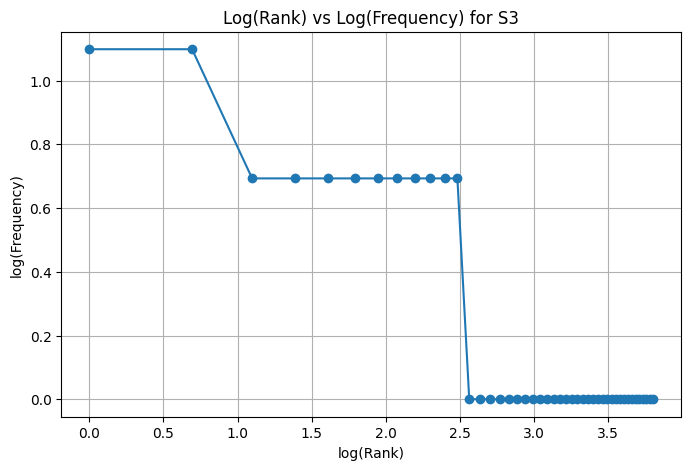


Top 5 bigrams of S1:
[(('.', 'the'), 5), (('failed', 'to'), 3), (('to', 'open'), 3), (('open', '.'), 3), (('.', 'is'), 3)]

Top 5 bigrams of S3:
[(('failed', 'open'), 3), (('problem', 'occurs'), 2), (('another', 'solution'), 2), (('uploading', 'file'), 2), (('projector', 'failed'), 1)]


In [10]:
# Your code

from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams
import string
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

S3 = [token for result in results for token in result["Final Tokens"]]

if "Tokens" in results[0]:
    S1 = [token for result in results for token in result["Tokens"]]
elif "tokens" in results[0]:
    S1 = [token for result in results for token in result["tokens"]]
else:
    S1 = [
        token
        for result in results
        for token in result.get("All Tokens", result.get("all_tokens", []))
    ]

if not S1:
    raise KeyError(
        f"Could not identify the all-tokens key. Available keys: {list(results[0].keys())}"
    )

S2 = [
    token for token in S1
    if token not in string.punctuation
]

porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1 (All Tokens)": S1,
    "S2 (No Punctuation)": S2,
    "S3 (Final Tokens)": S3,
    "S4 (Porter Stemmed)": S4
}

statistics = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    statistics.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

display(pd.DataFrame(statistics))

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

frequencies = Counter(S3).most_common()
ranks = np.arange(1, len(frequencies) + 1)
counts = np.array([frequency for word, frequency in frequencies])

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(counts), marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("\nTop 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR increases from 0.4265 in S1 to 0.5435 in S4 because punctuation removal, stopword removal, and stemming change the ratio of unique tokens to total tokens. S4 contains the same 92 tokens as S3, but Porter stemming reduces the unique tokens from 54 to 50 by combining different word forms into common stems. Therefore, TTR decreases from S3 (0.5870) to S4 (0.5435), while remaining higher than S1.

In [11]:
# 6. Interpretation
# (a) Why does TTR change from S1 to S4 in your dataset?
# TTR increases from 0.4265 in S1 to 0.5435 in S4 because preprocessing removes punctuation and stopwords, reducing the total number of tokens. Stemming then combines related word forms, reducing the number of unique tokens from 54 to 50 compared with S3. Overall, the reduction in total tokens makes the final TTR higher than S1.
# (b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
# For T01, which contains “state-of-the-art”, my tokenizer keeps state-of-the-art as a single token, whereas word_tokenize() may split it into multiple tokens around the hyphens. This happens because the two tokenizers follow different tokenization rules.
# (c) Give one example where stemming produces an undesirable result.
# The Regexp Stemmer changes syncing to synt, which is an undesirable result because it does not preserve the meaningful root of the word. This demonstrates that rule-based stemming can produce distorted word forms.
# (d) Give one example where POS-aware lemmatization preserves meaning better than stemming.
# The word opening is a good example. WordNet lemmatization with the appropriate part of speech can reduce opening to open, preserving its intended meaning. Porter stemming leaves opening unchanged in our output, while a POS-aware lemmatizer can return the meaningful dictionary form.